# 07. Verificación de los experimentos

Este cuaderno **vuelve a ejecutar** los experimentos de la Fase 3 y deja un registro real de lo que pasa:

1. Elige las primeras imágenes del experimento principal (misma semilla, 42).
2. Genera sus máscaras: tres cuadrados, dos círculos, un arañazo, motas y una forma irregular.
3. Aplica los tres métodos (media de los cuatro vecinos, Bertalmio y ejemplares), midiendo el tiempo y el error **en este momento**.
4. Guarda una tabla (`registro.csv` y `registro.md`) y una figura por caso en `resultados/verificacion/<fecha>/`.
5. Compara cada fila con el experimento principal (`resultados/experimentos.csv`): el error tiene que ser el mismo, porque los métodos son deterministas, y el tiempo, parecido.

Nada de lo que sale aquí está escrito a mano: lo calcula `src/verificar.py` al ejecutarse.

Para repetir **todo** el experimento principal, cambiar `IMAGENES = 3` por `20` (unos 25 minutos).

In [1]:
import os, sys, csv
sys.path.insert(0, os.path.abspath("../src"))
os.chdir(os.path.abspath(".."))      # carpeta del repositorio

import verificar
import metricas

IMAGENES = 3
print(metricas.informacion_equipo())

{'sistema': 'macOS-27.0.1-arm64-arm-64bit-Mach-O', 'procesador': 'arm', 'nucleos': 10, 'memoria_gb': 17.2, 'python': '3.14.6', 'numpy': '2.5.4', 'opencv': '5.0.0'}


## Ejecución

Imprime una línea por cada imagen, máscara y método.

In [2]:
destino, filas = verificar.verificar("images/originales", IMAGENES, 256, "resultados/verificacion")

[1/3] photo-1441802910857-d6c7 cuadrado_16    media        0.008 s  MSE hueco  1691.76  sí


[1/3] photo-1441802910857-d6c7 cuadrado_16    Bertalmio    0.919 s  MSE hueco  1884.36  sí


[1/3] photo-1441802910857-d6c7 cuadrado_16    ejemplares   0.461 s  MSE hueco  3910.94  sí


[1/3] photo-1441802910857-d6c7 cuadrado_32    media        0.028 s  MSE hueco  2316.79  sí


[1/3] photo-1441802910857-d6c7 cuadrado_32    Bertalmio    2.250 s  MSE hueco  2385.75  sí


[1/3] photo-1441802910857-d6c7 cuadrado_32    ejemplares   1.235 s  MSE hueco  3762.08  sí


... (63 outputs left out)

[3/3] photo-1473366311188-fb0d irregular_51   media        0.273 s  MSE hueco  1007.30  sí


[3/3] photo-1473366311188-fb0d irregular_51   Bertalmio    4.524 s  MSE hueco   382.69  sí


[3/3] photo-1473366311188-fb0d irregular_51   ejemplares   2.738 s  MSE hueco   400.10  sí



Verificación terminada en 166.9 s. Registro en resultados/verificacion/2026-11-26_0918


## Registro guardado

Es el contenido de `registro.md`, que se genera con las mismas filas.

In [3]:
from IPython.display import Markdown, display
display(Markdown(open(os.path.join(destino, "registro.md"), encoding="utf-8").read()))

# Registro de verificación de los experimentos (2026-11-26_0918)

Generado automáticamente por `src/verificar.py`: cada fila es una ejecución real hecha en el momento.

- Equipo: macOS-27.0.1-arm64-arm-64bit-Mach-O · arm64 · Python 3.14.6
- Bibliotecas: NumPy 2.5.4, OpenCV 5.0.0
- Imágenes: 3 (ancho 256 px, semilla 42); 72 ejecuciones en 167 s
- Coincidencia del error con el experimento principal: 72 de 72 filas

| Imagen | Máscara | Hueco (px) | Método | Tiempo (s) | Iter. | MSE hueco | PSNR hueco | MSE imagen | ¿Mismo error que el experimento? |
|---|---|---:|---|---:|---:|---:|---:|---:|:---:|
| photo-1441802910857-d6 | cuadrado_16 | 256 | media | 0.0083 | 208 | 1691.76 | 15.85 | 9.667 | sí |
| photo-1441802910857-d6 | cuadrado_16 | 256 | Bertalmio | 0.9189 | 467 | 1884.36 | 15.38 | 10.768 | sí |
| photo-1441802910857-d6 | cuadrado_16 | 256 | ejemplares | 0.4612 | 11 | 3910.94 | 12.21 | 22.348 | sí |
| photo-1441802910857-d6 | cuadrado_32 | 1024 | media | 0.0281 | 282 | 2316.79 | 14.48 | 52.955 | sí |
| photo-1441802910857-d6 | cuadrado_32 | 1024 | Bertalmio | 2.2500 | 600 | 2385.75 | 14.35 | 54.531 | sí |
| photo-1441802910857-d6 | cuadrado_32 | 1024 | ejemplares | 1.2347 | 37 | 3762.08 | 12.38 | 85.990 | sí |
| photo-1441802910857-d6 | cuadrado_64 | 4096 | media | 0.3275 | 938 | 2750.72 | 13.74 | 251.495 | sí |
| photo-1441802910857-d6 | cuadrado_64 | 4096 | Bertalmio | 5.7910 | 600 | 2588.40 | 14.00 | 236.654 | sí |
| photo-1441802910857-d6 | cuadrado_64 | 4096 | ejemplares | 4.5108 | 145 | 4340.88 | 11.76 | 396.881 | sí |
| photo-1441802910857-d6 | circulo_16 | 797 | media | 0.0456 | 518 | 2109.17 | 14.89 | 37.523 | sí |
| photo-1441802910857-d6 | circulo_16 | 797 | Bertalmio | 2.2322 | 600 | 2211.38 | 14.68 | 39.341 | sí |
| photo-1441802910857-d6 | circulo_16 | 797 | ejemplares | 1.0267 | 30 | 5105.23 | 11.05 | 90.823 | sí |
| photo-1441802910857-d6 | circulo_32 | 3209 | media | 0.1936 | 664 | 2055.25 | 15.00 | 147.216 | sí |
| photo-1441802910857-d6 | circulo_32 | 3209 | Bertalmio | 5.3158 | 600 | 2064.46 | 14.98 | 147.876 | sí |
| photo-1441802910857-d6 | circulo_32 | 3209 | ejemplares | 3.6578 | 114 | 3937.97 | 12.18 | 282.075 | sí |
| photo-1441802910857-d6 | aranazo_3 | 648 | media | 0.0053 | 44 | 1278.61 | 17.06 | 18.494 | sí |
| photo-1441802910857-d6 | aranazo_3 | 648 | Bertalmio | 4.0511 | 600 | 1542.50 | 16.25 | 22.311 | sí |
| photo-1441802910857-d6 | aranazo_3 | 648 | ejemplares | 1.6119 | 40 | 3104.19 | 13.21 | 44.900 | sí |
| photo-1441802910857-d6 | motas | 290 | media | 0.0260 | 59 | 1212.93 | 17.29 | 7.852 | sí |
| photo-1441802910857-d6 | motas | 290 | Bertalmio | 16.9649 | 600 | 1472.61 | 16.45 | 9.533 | sí |
| photo-1441802910857-d6 | motas | 290 | ejemplares | 0.7936 | 20 | 3095.03 | 13.22 | 20.035 | sí |
| photo-1441802910857-d6 | irregular_51 | 2519 | media | 0.1959 | 835 | 2276.05 | 14.56 | 127.977 | sí |
| photo-1441802910857-d6 | irregular_51 | 2519 | Bertalmio | 4.4849 | 600 | 2123.51 | 14.86 | 119.400 | sí |
| photo-1441802910857-d6 | irregular_51 | 2519 | ejemplares | 3.0090 | 93 | 2853.88 | 13.58 | 160.467 | sí |
| photo-1443750200537-00 | cuadrado_16 | 256 | media | 0.0076 | 185 | 1192.85 | 17.36 | 6.816 | sí |
| photo-1443750200537-00 | cuadrado_16 | 256 | Bertalmio | 0.5510 | 273 | 1374.59 | 16.75 | 7.855 | sí |
| photo-1443750200537-00 | cuadrado_16 | 256 | ejemplares | 0.4464 | 12 | 2658.47 | 13.88 | 15.191 | sí |
| photo-1443750200537-00 | cuadrado_32 | 1024 | media | 0.0385 | 372 | 246.33 | 24.22 | 5.630 | sí |
| photo-1443750200537-00 | cuadrado_32 | 1024 | Bertalmio | 2.2536 | 600 | 314.23 | 23.16 | 7.182 | sí |
| photo-1443750200537-00 | cuadrado_32 | 1024 | ejemplares | 1.3172 | 39 | 3991.65 | 12.12 | 91.238 | sí |
| photo-1443750200537-00 | cuadrado_64 | 4096 | media | 0.3547 | 1039 | 1036.66 | 17.97 | 94.780 | sí |
| photo-1443750200537-00 | cuadrado_64 | 4096 | Bertalmio | 5.7299 | 600 | 1132.90 | 17.59 | 103.579 | sí |
| photo-1443750200537-00 | cuadrado_64 | 4096 | ejemplares | 4.3588 | 143 | 2682.71 | 13.85 | 245.276 | sí |
| photo-1443750200537-00 | circulo_16 | 797 | media | 0.0383 | 406 | 1442.54 | 16.54 | 25.663 | sí |
| photo-1443750200537-00 | circulo_16 | 797 | Bertalmio | 2.1638 | 600 | 1800.86 | 15.58 | 32.038 | sí |
| photo-1443750200537-00 | circulo_16 | 797 | ejemplares | 1.0546 | 31 | 4194.05 | 11.90 | 74.613 | sí |
| photo-1443750200537-00 | circulo_32 | 3209 | media | 0.3075 | 1077 | 2944.76 | 13.44 | 210.932 | sí |
| photo-1443750200537-00 | circulo_32 | 3209 | Bertalmio | 5.3143 | 600 | 3002.01 | 13.36 | 215.032 | sí |
| photo-1443750200537-00 | circulo_32 | 3209 | ejemplares | 3.3886 | 110 | 3185.85 | 13.10 | 228.201 | sí |
| photo-1443750200537-00 | aranazo_3 | 648 | media | 0.0054 | 46 | 77.34 | 29.25 | 1.119 | sí |
| photo-1443750200537-00 | aranazo_3 | 648 | Bertalmio | 3.9569 | 600 | 120.65 | 27.32 | 1.745 | sí |
| photo-1443750200537-00 | aranazo_3 | 648 | ejemplares | 1.5601 | 40 | 372.77 | 22.42 | 5.392 | sí |
| photo-1443750200537-00 | motas | 290 | media | 0.0272 | 63 | 134.28 | 26.85 | 0.869 | sí |
| photo-1443750200537-00 | motas | 290 | Bertalmio | 6.7855 | 252 | 100.85 | 28.09 | 0.653 | sí |
| photo-1443750200537-00 | motas | 290 | ejemplares | 0.7424 | 19 | 235.49 | 24.41 | 1.524 | sí |
| photo-1443750200537-00 | irregular_51 | 2519 | media | 0.2265 | 975 | 1532.75 | 16.28 | 86.183 | sí |
| photo-1443750200537-00 | irregular_51 | 2519 | Bertalmio | 4.4772 | 600 | 1636.51 | 15.99 | 92.017 | sí |
| photo-1443750200537-00 | irregular_51 | 2519 | ejemplares | 2.7560 | 88 | 3416.11 | 12.80 | 192.080 | sí |
| photo-1473366311188-fb | cuadrado_16 | 256 | media | 0.0064 | 156 | 66.72 | 29.89 | 0.381 | sí |
| photo-1473366311188-fb | cuadrado_16 | 256 | Bertalmio | 0.7055 | 356 | 42.26 | 31.87 | 0.241 | sí |
| photo-1473366311188-fb | cuadrado_16 | 256 | ejemplares | 0.4439 | 12 | 67.46 | 29.84 | 0.385 | sí |
| photo-1473366311188-fb | cuadrado_32 | 1024 | media | 0.0355 | 354 | 518.79 | 20.98 | 11.858 | sí |
| photo-1473366311188-fb | cuadrado_32 | 1024 | Bertalmio | 2.2432 | 600 | 705.25 | 19.65 | 16.120 | sí |
| photo-1473366311188-fb | cuadrado_32 | 1024 | ejemplares | 1.4085 | 41 | 1198.83 | 17.34 | 27.402 | sí |
| photo-1473366311188-fb | cuadrado_64 | 4096 | media | 0.2613 | 761 | 1393.23 | 16.69 | 127.381 | sí |
| photo-1473366311188-fb | cuadrado_64 | 4096 | Bertalmio | 5.6252 | 600 | 1506.81 | 16.35 | 137.766 | sí |
| photo-1473366311188-fb | cuadrado_64 | 4096 | ejemplares | 4.5642 | 148 | 1773.93 | 15.64 | 162.188 | sí |
| photo-1473366311188-fb | circulo_16 | 797 | media | 0.0305 | 348 | 932.78 | 18.43 | 16.594 | sí |
| photo-1473366311188-fb | circulo_16 | 797 | Bertalmio | 2.1708 | 600 | 981.35 | 18.21 | 17.458 | sí |
| photo-1473366311188-fb | circulo_16 | 797 | ejemplares | 1.1118 | 32 | 1325.31 | 16.91 | 23.578 | sí |
| photo-1473366311188-fb | circulo_32 | 3209 | media | 0.2344 | 821 | 940.89 | 18.40 | 67.396 | sí |
| photo-1473366311188-fb | circulo_32 | 3209 | Bertalmio | 5.2665 | 600 | 1048.49 | 17.93 | 75.103 | sí |
| photo-1473366311188-fb | circulo_32 | 3209 | ejemplares | 3.6018 | 115 | 1707.54 | 15.81 | 122.310 | sí |
| photo-1473366311188-fb | aranazo_3 | 648 | media | 0.0057 | 49 | 124.31 | 27.19 | 1.798 | sí |
| photo-1473366311188-fb | aranazo_3 | 648 | Bertalmio | 3.9473 | 600 | 148.08 | 26.43 | 2.142 | sí |
| photo-1473366311188-fb | aranazo_3 | 648 | ejemplares | 1.5130 | 39 | 179.67 | 25.59 | 2.599 | sí |
| photo-1473366311188-fb | motas | 290 | media | 0.0249 | 57 | 152.83 | 26.29 | 0.989 | sí |
| photo-1473366311188-fb | motas | 290 | Bertalmio | 16.0621 | 600 | 97.77 | 28.23 | 0.633 | sí |
| photo-1473366311188-fb | motas | 290 | ejemplares | 0.7880 | 20 | 186.25 | 25.43 | 1.206 | sí |
| photo-1473366311188-fb | irregular_51 | 2519 | media | 0.2730 | 1175 | 1007.30 | 18.10 | 56.638 | sí |
| photo-1473366311188-fb | irregular_51 | 2519 | Bertalmio | 4.5237 | 600 | 382.69 | 22.30 | 21.517 | sí |
| photo-1473366311188-fb | irregular_51 | 2519 | ejemplares | 2.7382 | 87 | 400.10 | 22.11 | 22.497 | sí |

Las figuras de cada caso (original, máscara, dañada y los tres resultados) están en `figuras/`.


## Resumen por método

Media de las ejecuciones de este registro.

In [4]:
from collections import defaultdict
datos = defaultdict(list)
for f in filas:
    datos[f["metodo"]].append((float(f["tiempo_s"]), float(f["mse_hueco"]), float(f["psnr_hueco"])))
print(f"{'método':12s} {'tiempo medio (s)':>17s} {'MSE hueco medio':>16s} {'PSNR hueco medio':>17s}")
for metodo, v in datos.items():
    n = len(v)
    print(f"{metodo:12s} {sum(x[0] for x in v)/n:17.3f} {sum(x[1] for x in v)/n:16.1f} {sum(x[2] for x in v)/n:17.2f}")

iguales = sum(f["mismo_error"] == "sí" for f in filas)
print(f"\nError idéntico al del experimento principal en {iguales} de {len(filas)} ejecuciones.")

método        tiempo medio (s)  MSE hueco medio  PSNR hueco medio
media                    0.113           1226.5             19.20
Bertalmio                4.741           1277.8             19.16
ejemplares               2.004           2403.6             16.36

Error idéntico al del experimento principal en 72 de 72 ejecuciones.


## Comprobación con el experimento principal

Si alguna fila no coincide, se muestra aquí.

In [5]:
distintas = [f for f in filas if f["mismo_error"] == "NO"]
print("Filas con error distinto:", len(distintas))
for f in distintas:
    print(f["imagen"], f["mascara"], f["metodo"], "ahora", f["mse_hueco"], "antes", f["mse_hueco_experimento"])

# tiempos: ahora frente a los del experimento principal
for metodo in datos:
    pares = [(float(f["tiempo_s"]), float(f["tiempo_experimento_s"])) for f in filas if f["metodo"] == metodo and f["tiempo_experimento_s"]]
    if pares:
        print(f"{metodo:12s} tiempo ahora / tiempo del experimento = {sum(a for a,_ in pares)/sum(b for _,b in pares):.2f}")

Filas con error distinto: 0
media        tiempo ahora / tiempo del experimento = 1.01
Bertalmio    tiempo ahora / tiempo del experimento = 1.01
ejemplares   tiempo ahora / tiempo del experimento = 0.99


## Figuras de cada caso

Original, máscara, imagen dañada y resultado de cada método, con su MSE sobre el hueco y su tiempo.

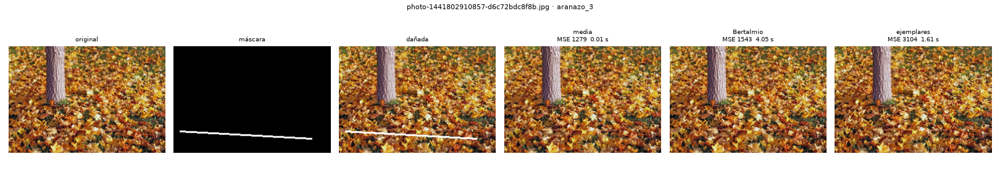

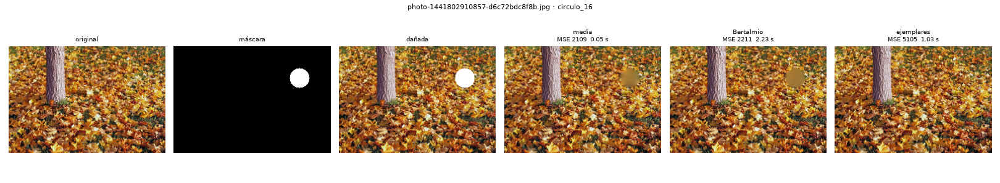

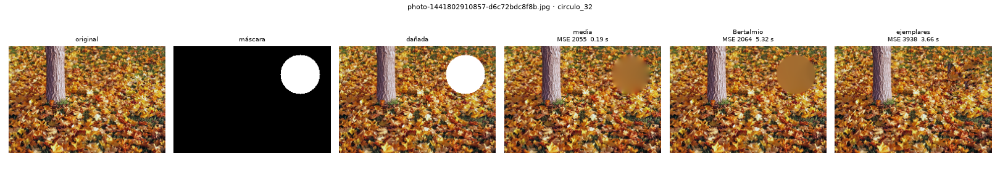

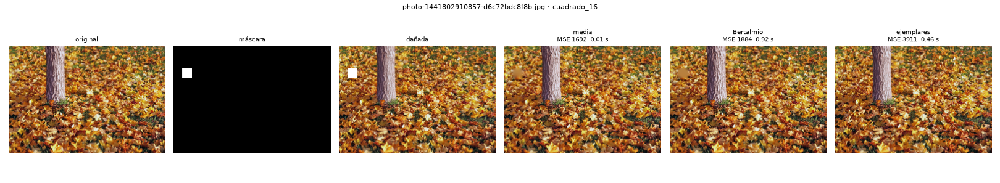

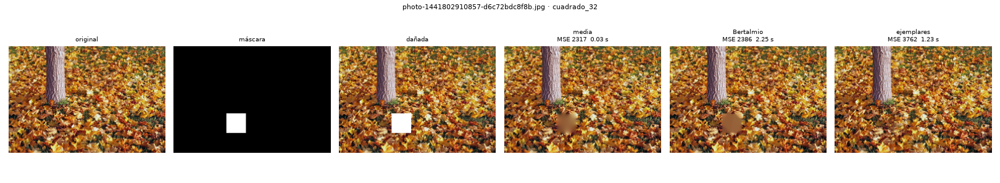

...

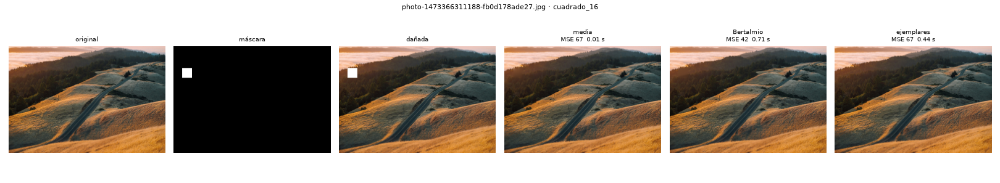

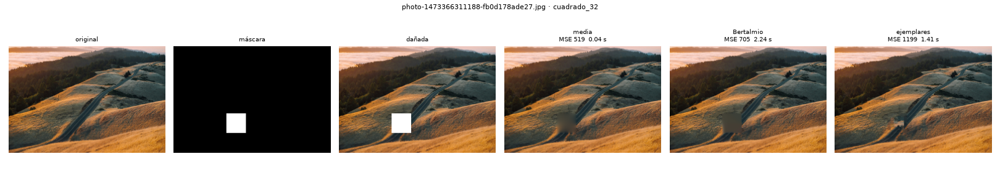

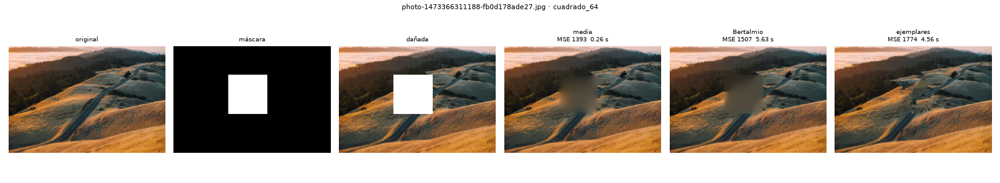

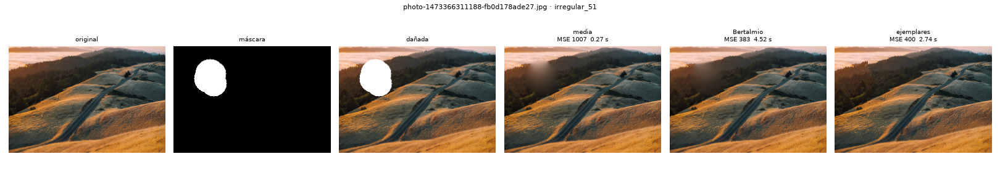

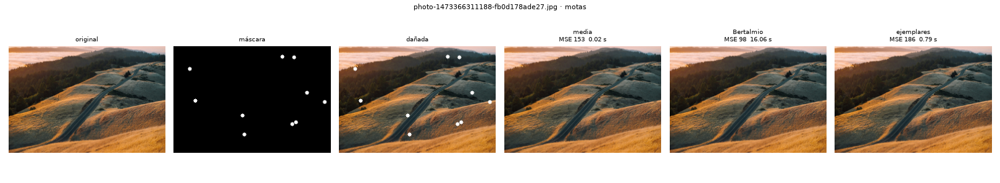

In [6]:
from IPython.display import Image
carpeta = os.path.join(destino, "figuras")
for nombre in sorted(os.listdir(carpeta)):
    display(Image(filename=os.path.join(carpeta, nombre)))